[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Elheims/scikit-learn-cookbook/blob/main/04.%20Models%20with%20Distance%20Metrics%20and%20Nearest%20Neighbors/ch04_distance_metrics_knn.ipynb)

# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

**Book:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt) — Chapter 4, pp. 92–115

**What you will learn in this chapter:**
- What "distance" means in machine learning, and the Euclidean, Manhattan and Minkowski metrics
- How the k-nearest neighbours (KNN) algorithm classifies (and regresses) from similarity
- How the choice of `k`, of the distance metric and of the voting weights changes a KNN model
- How to tune KNN with `GridSearchCV` (and `RandomizedSearchCV`) using cross-validation
- How to evaluate a classifier: cross-validation scores, learning curves, confusion matrix, precision / recall / F1
- How to handle imbalanced data when evaluating, and three end-of-chapter exercises on different datasets

## Chapter summary

| Section | Core idea | Key API |
|---|---|---|
| Distance metrics | Similarity = small distance; L1, L2, Lp | `metric=`, `p=` |
| Understanding KNN | Predict from the majority (or mean) of the k closest training points | `KNeighborsClassifier` |
| Distance metrics overview | Metric choice can change accuracy; scale and dimension matter | `make_circles`, `metric` |
| Hyperparameter tuning | Search `n_neighbors`, `weights`, `metric` with CV | `GridSearchCV` |
| Evaluating KNN | Learning curve, confusion matrix, classification report | `learning_curve`, `confusion_matrix`, `classification_report` |
| Practical exercises | Build, tune and evaluate KNN on real datasets | `Pipeline` |

**How this notebook is organised.** Each section has a summary, the book's code reproduced and executed, and a *Theory* cell.
Cells marked **Extension** are not in the book's code. Places where the book's text or code is inaccurate or incomplete are flagged
with **Book correction** (collected again at the end). The book's snippets omit some imports (`cross_val_score`, `classification_report`,
`pandas`, `numpy`, `matplotlib`); they are added here.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

print("scikit-learn version:", sklearn.__version__)
print("NumPy version       :", np.__version__)

scikit-learn version: 1.9.1
NumPy version       : 2.5.3


## 1. Introduction to distance metrics

**Summary.** Many algorithms rely on *similarity* between data points: classification (KNN), clustering (K-Means, Chapter 10), regression and anomaly detection.
Similarity is measured as a **distance** between feature vectors — small distance means similar. The book introduces three distances:

| Metric | Idea | Formula (for vectors $a, b$ with $n$ features) |
|---|---|---|
| **Euclidean** (L2) | straight-line, "as the crow flies" | $\sqrt{\sum_i (a_i-b_i)^2}$ |
| **Manhattan** (L1, city-block) | move only along axes, like streets in a grid; less dominated by one large difference | $\sum_i \lvert a_i-b_i\rvert$ |
| **Minkowski** (Lp) | generalisation controlled by the parameter $p$ | $\left(\sum_i \lvert a_i-b_i\rvert^{p}\right)^{1/p}$ |

$p=1$ gives Manhattan, $p=2$ gives Euclidean, $p\to\infty$ gives Chebyshev (the largest single difference).

**Extension — computing the distances by hand and with scikit-learn** (also cosine, Hamming and Jaccard, which appear in the book's decision guide):

In [2]:
from sklearn.metrics import pairwise_distances
from scipy.spatial import distance as sd

a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 0.0, 3.0])

print("difference vector:", b - a)
print("Euclidean  by hand:", np.sqrt(((a - b) ** 2).sum()).round(4), "| sklearn:", pairwise_distances([a], [b], metric="euclidean")[0, 0].round(4))
print("Manhattan  by hand:", np.abs(a - b).sum(), "          | sklearn:", pairwise_distances([a], [b], metric="manhattan")[0, 0])
for p in (1, 2, 3, 10):
    print(f"Minkowski p={p:<2}  by hand:", ((np.abs(a - b) ** p).sum() ** (1 / p)).round(4), "| sklearn:", pairwise_distances([a], [b], metric="minkowski", p=p)[0, 0].round(4))
print("Chebyshev  (p -> inf):", np.abs(a - b).max())
print("Cosine distance      :", round(sd.cosine(a, b), 4), "  (1 - cos(angle between the vectors))")

u = np.array([1, 0, 1, 1, 0, 1]); v = np.array([1, 1, 0, 1, 0, 0])
print("\nbinary vectors u =", u, " v =", v)
print("Hamming  (fraction of positions that differ):", sd.hamming(u, v))
print("Jaccard  (1 - |intersection| / |union|)     :", round(sd.jaccard(u, v), 4))

difference vector:

 [ 3. -2.  0.]
Euclidean  by hand: 3.6056 | sklearn: 3.6056
Manhattan  by hand: 5.0           | sklearn: 5.0
Minkowski p=1   by hand: 5.0 | sklearn: 5.0
Minkowski p=2   by hand: 3.6056 | sklearn: 3.6056
Minkowski p=3   by hand: 3.2711 | sklearn: 3.2711
Minkowski p=10  by hand: 3.0052 | sklearn: 3.0052
Chebyshev  (p -> inf): 3.0
Cosine distance      : 0.3051   (1 - cos(angle between the vectors))

binary vectors u = [1 0 1 1 0 1]  v = [1 1 0 1 0 0]
Hamming  (fraction of positions that differ): 0.5
Jaccard  (1 - |intersection| / |union|)     : 0.6


### Theory
* **What makes a metric?** A function $d$ with $d(a,b)\ge0$, $d(a,b)=0\iff a=b$, symmetry $d(a,b)=d(b,a)$ and the triangle inequality $d(a,c)\le d(a,b)+d(b,c)$. Cosine *distance* is not a true metric (the triangle inequality can fail) but is widely used.
* **Euclidean** squares the differences, so one large coordinate difference dominates; **Manhattan** adds absolute differences, so it is somewhat more robust to a single outlying feature and
  is often preferred in high dimensions. **Larger $p$** emphasises the largest coordinate difference more.
* **Scale matters.** All Lp distances add up raw coordinate differences, so a feature measured in thousands swamps one measured in fractions (the effect measured in Chapter 2). Standardise first.
* **Choosing a metric** follows the data type (see the decision guide in Section 2): continuous → L2/L1; text/sparse directional → cosine; sets/binary → Jaccard; fixed-length categorical/binary strings → Hamming.

## 2. Understanding KNNs

**Summary.** *k-nearest neighbours* is a supervised algorithm for classification and regression. To predict for a new point: find the `k` training points nearest to it
(using a distance metric) and let them **vote** (classification: majority class) or **average** (regression).

### Getting ready — the Iris dataset
150 flowers, 3 species, 4 measurements (cm).

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)
print("train:", X_train.shape, "test:", X_test.shape, "| class counts in train:", np.bincount(y_train))
print(pd.DataFrame(X, columns=iris.feature_names).describe().loc[["mean", "std", "min", "max"]].round(2).to_string())

train: (120, 4) test: (30, 4) | class counts in train: [38 42 40]
      sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
mean               5.84              3.06               3.76              1.20
std                0.83              0.44               1.77              0.76
min                4.30              2.00               1.00              0.10
max                7.90              4.40               6.90              2.50


Iris features are all in centimetres and of similar magnitude, so scaling matters little here (it will matter on other data later in the chapter).

### How to do it…

In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


The book reports `Accuracy: 0.9333…` for this split. Our number is shown above. (With 30 test samples one extra mistake changes accuracy by 3.3 points, so small differences between
library versions or splits are normal.)

### How it works…
The three ingredients named in the book: **choose `k`**, **compute distances**, **vote**. KNN has **no training phase** in the usual sense — `fit` just stores the data
(a *lazy*, or memory-based, learner); all the work happens at prediction time.

**Extension — KNN from scratch (20 lines of NumPy) matches scikit-learn exactly:**

In [5]:
def knn_predict(X_tr, y_tr, X_new, k=3):
    preds = []
    for x in X_new:
        d = np.sqrt(((X_tr - x) ** 2).sum(axis=1))      # 1. distance to every training point
        nearest = np.argsort(d)[:k]                     # 2. indices of the k closest
        votes = np.bincount(y_tr[nearest])              # 3. count the labels
        preds.append(votes.argmax())                    #    majority vote
    return np.array(preds)

mine = knn_predict(X_train, y_train, X_test, k=3)
print("identical to sklearn predictions:", (mine == y_pred).all())

# a closer look at one test point
x0 = X_test[0]; d0 = np.sqrt(((X_train - x0) ** 2).sum(axis=1)); idx = np.argsort(d0)[:3]
print("\ntest point:", x0, "-> true class", y_test[0])
print("3 nearest training points' distances:", d0[idx].round(3), "| their classes:", y_train[idx], "| vote ->", np.bincount(y_train[idx]).argmax())
print("neighbours of the same point via sklearn:", knn.kneighbors([x0], return_distance=True)[0].round(3))
print("class probabilities = vote shares:", knn.predict_proba([x0]))

identical to sklearn predictions: True

test point: [5.8 4.  1.2 0.2] -> true class 0
3 nearest training points' distances: [0.412 0.469 0.557] | their classes: [0 0 0] | vote -> 0
neighbours of the same point via sklearn: [[0.412 0.469 0.557]]
class probabilities = vote shares: [[1. 0. 0.]]


### "Visualizing how KNN classifies points … decision boundaries formed by different values of k"
The book suggests plotting decision boundaries for different `k`; here it is, on two Iris features (petal length and width) so that it can be drawn in 2-D.

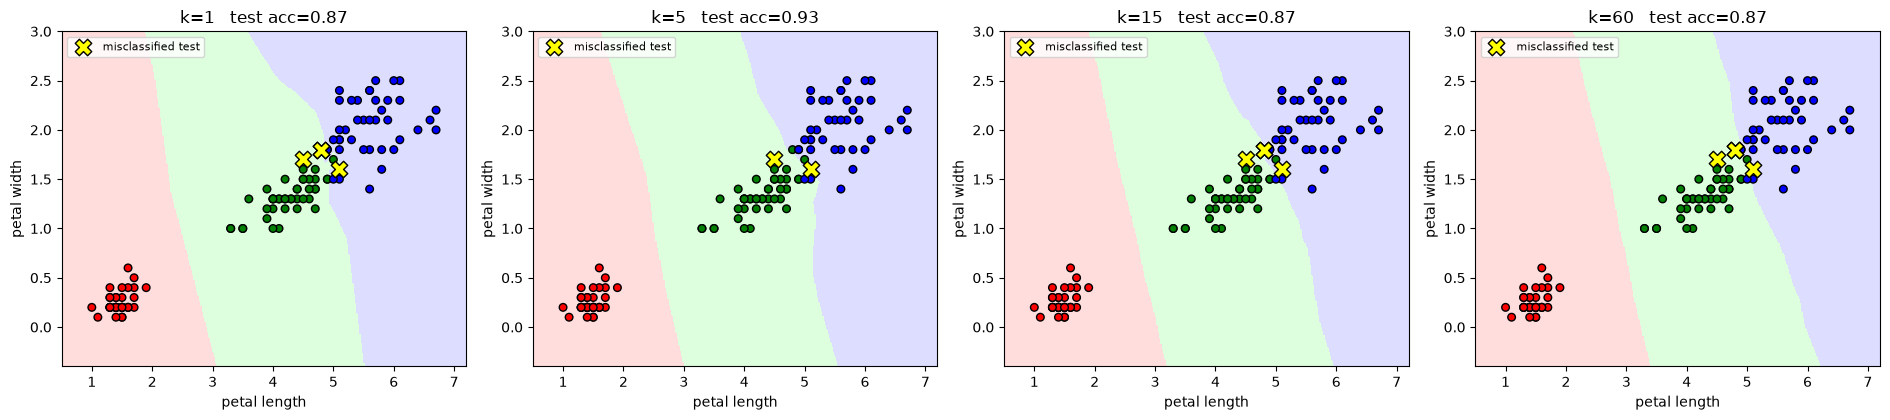

In [6]:
from matplotlib.colors import ListedColormap

feat = [2, 3]                                          # petal length, petal width
Xp_train, Xp_test = X_train[:, feat], X_test[:, feat]
xx, yy = np.meshgrid(np.linspace(Xp_train[:, 0].min() - .5, Xp_train[:, 0].max() + .5, 300),
                     np.linspace(Xp_train[:, 1].min() - .5, Xp_train[:, 1].max() + .5, 300))
cmap_bg = ListedColormap(["#fdd", "#dfd", "#ddf"]); cmap_pt = ListedColormap(["r", "g", "b"])

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, k in zip(axes, (1, 5, 15, 60)):
    m = KNeighborsClassifier(n_neighbors=k).fit(Xp_train, y_train)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg)
    ax.scatter(Xp_train[:, 0], Xp_train[:, 1], c=y_train, cmap=cmap_pt, edgecolor="k", s=30)
    wrong = m.predict(Xp_test) != y_test                # highlight misclassified test points
    ax.scatter(Xp_test[wrong, 0], Xp_test[wrong, 1], marker="X", c="yellow", edgecolor="k", s=140, label="misclassified test")
    ax.set_title(f"k={k}   test acc={m.score(Xp_test, y_test):.2f}"); ax.set_xlabel("petal length"); ax.set_ylabel("petal width")
    if wrong.any(): ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

On these two petal features the species are well separated, so the effect of `k` is **subtle** rather than dramatic:
* **k = 1:** the versicolor/virginica boundary is slightly wavy and bends around individual training points (low bias, high variance — it follows noise).
* **k = 5–15:** a smoother boundary.
* **k = 60:** an almost straight boundary that is shifted by the many far-away neighbours that now vote (high bias; with even larger `k` it would drift further, *underfitting*).
* The **same three test points** (yellow crosses) are misclassified at every `k`: they sit in the overlap zone between versicolor and virginica, so no value of `k` can fix them. The small
  differences in test accuracy (0.87 vs 0.93 = one test point) are within noise for 30 test samples — which is why `k` should be chosen by cross-validation, not by one split.

### There's more… choosing `k` and the distance metric
The book names two strategies: **cross-validation** over `k`, and the **elbow method** (plot accuracy vs `k` and look for diminishing returns).

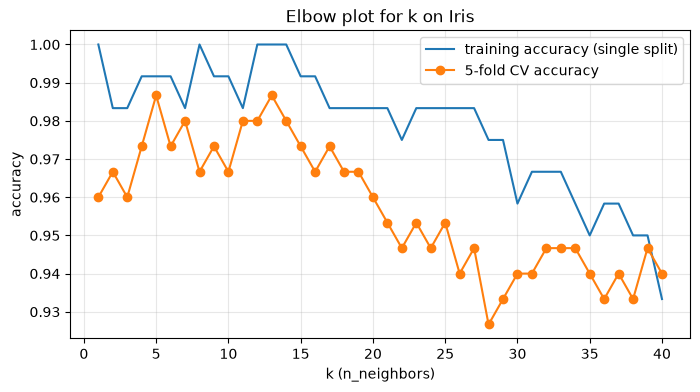

best k by CV: 5 with accuracy 0.987


In [7]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ks = range(1, 41)
cv = StratifiedKFold(5, shuffle=True, random_state=2024)
cv_mean = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X, y, cv=cv).mean() for k in ks]
train_acc = [KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).score(X_train, y_train) for k in ks]

plt.figure(figsize=(8, 4))
plt.plot(ks, train_acc, label="training accuracy (single split)")
plt.plot(ks, cv_mean, "o-", label="5-fold CV accuracy")
plt.xlabel("k (n_neighbors)"); plt.ylabel("accuracy"); plt.title("Elbow plot for k on Iris"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("best k by CV:", list(ks)[int(np.argmax(cv_mean))], "with accuracy", round(max(cv_mean), 3))

Training accuracy starts at 1.0 for `k=1` (each point is its own nearest neighbour) and falls as `k` grows; CV accuracy is flat-topped over a wide range of `k` — exactly the
"diminishing returns" the elbow method looks for. On a dataset this easy many values of `k` are equivalent, so prefer the simpler/odd/smoother one.

### Distance-metric decision guide (book's Figure 4.1) as a table
| Data type | Structure / focus | Metric | Good for |
|---|---|---|---|
| Numerical / continuous | grid, city blocks | **Manhattan** (L1) | grid paths, feature selection |
| | natural clusters | **Euclidean** (L2) | clustering, KNN |
| | different scales | **Standardised Euclidean** (scale first) | mixed units |
| Text / sparse | direction / angle | **Cosine** | text, recommendations |
| | set overlap | **Jaccard** | binary features, sets |
| Categorical / binary | fixed-length strings | **Hamming** | binary strings, DNA |
| | variable-length strings | **Levenshtein** (edit distance) | spell check, fuzzy matching |
| Time series / sequences | shape / pattern | **Correlation distance** ($1-r$) | trend similarity |
| | variable-length / warped | **DTW** (dynamic time warping) | speech, gestures |

(scikit-learn's `KNeighborsClassifier` supports Euclidean, Manhattan, Minkowski, Chebyshev, cosine, Hamming, Jaccard, … directly; Levenshtein and DTW are not built in — a callable
`metric=` or a library such as `tslearn` is needed.)

### Theory
* **Algorithm.** For a query $x$: $N_k(x)$ = the $k$ training points with smallest $d(x,x_i)$. Classification: $\hat y=\arg\max_c\sum_{i\in N_k(x)}\mathbb 1[y_i=c]$. Regression: $\hat y=\frac1k\sum_{i\in N_k(x)}y_i$.
  `predict_proba` returns the vote shares.
* **Bias–variance and `k`.** Small `k` → flexible boundary, low bias, high variance (overfits noise). Large `k` → smooth boundary, high bias, low variance. In the limit `k = n` KNN always predicts the majority class.
  Use odd `k` in binary problems to avoid ties.
* **Lazy learner.** No parameters are learned; the "model" is the training set. Prediction costs $O(n\,d)$ per query by brute force; `KDTree`/`BallTree` speed this up in low dimensions (see the Extension in Section 3).
* **Assumptions / weaknesses.** Nearby points have similar labels; needs scaled, relevant features; suffers from the curse of dimensionality (distances concentrate — Chapter 3), noisy features and class imbalance (the majority class dominates the vote).
  Memory- and prediction-heavy for large datasets.
* **Hyper-parameters:** `n_neighbors`, `weights` (`'uniform'` or `'distance'`), `metric` and `p`, `algorithm`.

### Hands-on workflow (from the book)
Load `KNeighborsClassifier` → try several `k` → score with accuracy / confusion matrix → try other metrics → plot decision boundaries and highlight misclassified points (all done above).

## 3. Distance metrics overview

**Summary.** The metric can change which neighbours are "nearest" and hence the predictions. The book compares metrics on two synthetic datasets built to favour different distances.

### Getting ready
* **Noisy circles** — two concentric noisy rings (the book expects Euclidean to work well).
* **Checkerboard** — a regular grid whose cells alternate class (the book expects Manhattan to work well).

> **Book corrections for this recipe.** (1) `make_circles` is called without a `random_state`, so every run draws a different dataset — I set `random_state=2024` for reproducibility.
> (2) The grid has `int(sqrt(300)) = 17` points per side, i.e. **289** points, not 300. (3) The variables are named `*_moons` but the data is a checkerboard, not the "two moons" dataset.

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

n_samples = 300

# This is the circular dataset with high noise (Euclidean distance should work better)
X_circles, y_circles = make_circles(
    n_samples=n_samples,
    noise=0.3, factor=0.3, random_state=2024
)
X_circles_train, X_circles_test, \
    y_circles_train, y_circles_test = train_test_split(
        X_circles, y_circles,
        test_size=0.2, random_state=2024
)

# This is the checkerboard pattern dataset (Manhattan distance should work better)
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
y = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, y)
X_moons = np.column_stack((xx.ravel(), yy.ravel()))
y_moons = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)
X_moons_train, X_moons_test, \
    y_moons_train, y_moons_test = train_test_split(
        X_moons, y_moons,
        test_size=0.2, random_state=2024
)
print("circles:", X_circles.shape, "| checkerboard:", X_moons.shape)

circles: (300, 2) | checkerboard: (289, 2)


### How to do it…
Fit a 3-NN classifier with each metric on each dataset and compare test accuracy.

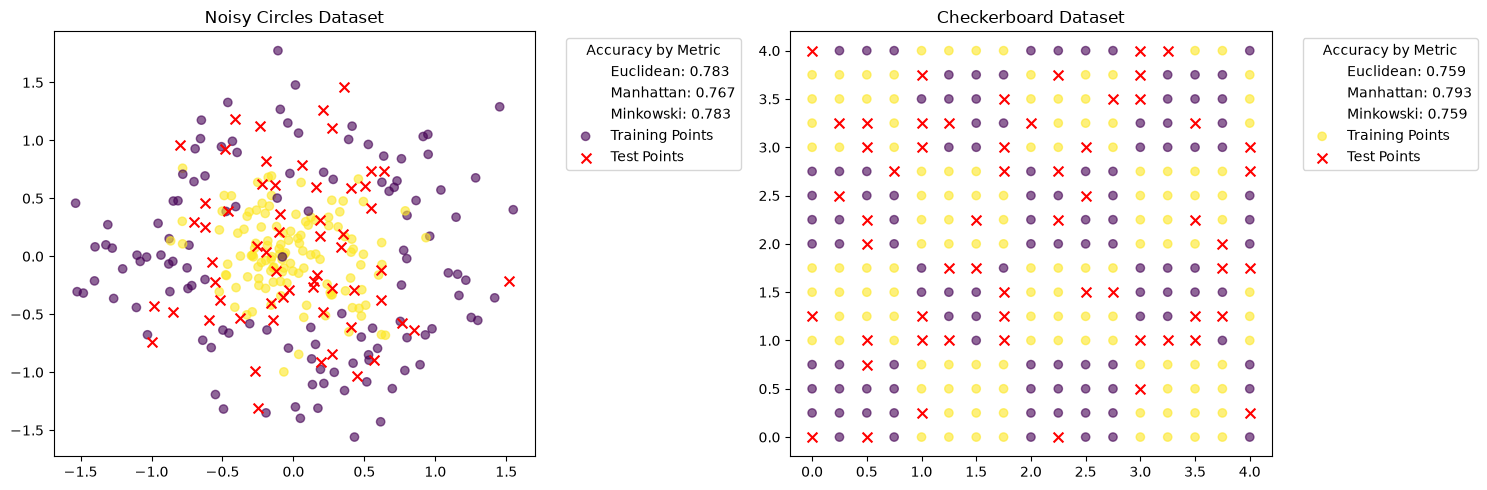

In [9]:
metrics = ['euclidean', 'manhattan', 'minkowski']
results = {'circles': {}, 'moons': {}}
for metric in metrics:
    # Test on circles dataset
    knn_circles = KNeighborsClassifier(n_neighbors=3,
                                       metric=metric)
    knn_circles.fit(X_circles_train, y_circles_train)
    y_pred_circles = knn_circles.predict(X_circles_test)
    results['circles'][metric] = accuracy_score(
        y_circles_test, y_pred_circles)

    # Test on moons dataset
    knn_moons = KNeighborsClassifier(n_neighbors=3,
                                     metric=metric)
    knn_moons.fit(X_moons_train, y_moons_train)
    y_pred_moons = knn_moons.predict(X_moons_test)
    results['moons'][metric] = accuracy_score(y_moons_test,
                                              y_pred_moons)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Circles
scatter1_train = ax1.scatter(
    X_circles_train[:, 0], X_circles_train[:, 1],
    c=y_circles_train, cmap='viridis',
    alpha=0.6, label='Training Points'
)
scatter1_test = ax1.scatter(
    X_circles_test[:, 0], X_circles_test[:, 1],
    color='red', marker='x', s=50,
    label='Test Points'
)
ax1.set_title('Noisy Circles Dataset')
lines1 = [plt.Line2D([0], [0], color='white')
          for _ in metrics]
legend_text1 = [
    f"Euclidean: {results['circles']['euclidean']:.3f}",
    f"Manhattan: {results['circles']['manhattan']:.3f}",
    f"Minkowski: {results['circles']['minkowski']:.3f}"
]
ax1.legend(
    lines1 + [scatter1_train, scatter1_test],
    legend_text1 + ['Training Points', 'Test Points'],
    title='Accuracy by Metric',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

# Checkerboard
scatter2_train = ax2.scatter(
    X_moons_train[:, 0], X_moons_train[:, 1],
    c=y_moons_train, cmap='viridis',
    alpha=0.6, label='Training Points'
)
scatter2_test = ax2.scatter(
    X_moons_test[:, 0], X_moons_test[:, 1],
    color='red', marker='x', s=50,
    label='Test Points'
)
ax2.set_title('Checkerboard Dataset')
lines2 = [plt.Line2D([0], [0], color='white')
          for _ in metrics]
legend_text2 = [
    f"Euclidean: {results['moons']['euclidean']:.3f}",
    f"Manhattan: {results['moons']['manhattan']:.3f}",
    f"Minkowski: {results['moons']['minkowski']:.3f}"
]
ax2.legend(
    lines2 + [scatter2_train, scatter2_test],
    legend_text2 + ['Training Points', 'Test Points'],
    title='Accuracy by Metric',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

> **Book correction — Minkowski equals Euclidean here.** In scikit-learn `metric="minkowski"` uses `p=2` by default, which *is* the Euclidean distance. That is why the book's
> "Euclidean" and "Minkowski" accuracies are identical (0.833 / 0.833 and 0.759 / 0.759 in its figure) — only two *different* metrics were compared.
> To get a genuinely different Minkowski metric you must set `p` (e.g. `p=3`).

The book concludes that Manhattan "seems to provide the best estimation … possibly simply by luck" on the circles. With only 60 test points a single sample is 1.7 points, so a
single run says very little. **Extension — repeat the experiment many times** (30 fresh datasets for the circles; 30 repeated stratified splits for the checkerboard) and add
genuinely different metrics (`minkowski` with `p=3`, `chebyshev`, `cosine`):

In [10]:
from sklearn.model_selection import RepeatedStratifiedKFold

metric_specs = {
    "euclidean":        dict(metric="euclidean"),
    "manhattan":        dict(metric="manhattan"),
    "minkowski p=3":    dict(metric="minkowski", p=3),
    "chebyshev":        dict(metric="chebyshev"),
    "cosine":           dict(metric="cosine", algorithm="brute"),
}

# 30 independent noisy-circles datasets
circ = {name: [] for name in metric_specs}
for seed in range(30):
    Xc, yc = make_circles(n_samples=300, noise=0.3, factor=0.3, random_state=seed)
    Xa, Xb, ya, yb = train_test_split(Xc, yc, test_size=0.2, random_state=seed)
    for name, kw in metric_specs.items():
        circ[name].append(KNeighborsClassifier(n_neighbors=3, **kw).fit(Xa, ya).score(Xb, yb))

# checkerboard: repeated 5-fold CV (cosine omitted: it ignores the distance from the origin, meaningless for a grid)
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=6, random_state=0)
checker = {name: cross_val_score(KNeighborsClassifier(n_neighbors=3, **kw), X_moons, y_moons, cv=rskf)
           for name, kw in metric_specs.items() if name != "cosine"}

summary = pd.DataFrame({
    "circles: mean acc (30 datasets)": {k: np.mean(v) for k, v in circ.items()},
    "circles: std": {k: np.std(v) for k, v in circ.items()},
    "checkerboard: mean acc (30 splits)": {k: np.mean(v) for k, v in checker.items()},
    "checkerboard: std": {k: np.std(v) for k, v in checker.items()},
}).round(3)
summary

,circles: mean acc (30 datasets),circles: std,checkerboard: mean acc (30 splits),checkerboard: std
euclidean,0.829,0.041,0.829,0.045
manhattan,0.831,0.040,0.831,0.048
minkowski p=3,0.829,0.041,0.831,0.045
chebyshev,0.829,0.042,0.687,0.053
cosine,0.503,0.064,NaN,NaN


Reading the table: on the noisy circles all the Lp metrics are within one standard deviation of each other (the book's Manhattan "win" is noise), and `cosine` is clearly worse because
it only sees the *angle* from the origin, which is meaningless for rings. On the checkerboard, Manhattan, Euclidean and Minkowski-3 are again statistically indistinguishable
(0.83 ± 0.05) — the book's expectation that Manhattan is clearly better is not borne out — while **Chebyshev is much worse (0.69)**: it only looks at the single largest coordinate difference, so on a regular
grid many points are exactly tied and the neighbour choice becomes arbitrary. (`cosine` is shown as NaN for the checkerboard because it was deliberately skipped: the angle from the origin is meaningless for a grid.)
Always judge a metric with repeated resampling or cross-validation, as the book's own advice says.

### How it works…
The book's descriptions: **Euclidean** — most common, sensitive to outliers, best when features are scaled alike; **Manhattan** — less sensitive to outliers;
**Minkowski** — generalises both through `p`.

### Impact on model performance
* **Sensitivity to scale** — standardise/normalise before KNN. **Extension — measured on the Wine data:**

In [11]:
from sklearn.datasets import load_wine
Xw, yw = load_wine(return_X_y=True)

rows = []
for name, kw in {"euclidean": dict(metric="euclidean"), "manhattan": dict(metric="manhattan"), "chebyshev": dict(metric="chebyshev")}.items():
    raw = cross_val_score(KNeighborsClassifier(**kw), Xw, yw, cv=cv).mean()
    scaled = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(**kw)), Xw, yw, cv=cv).mean()
    rows.append({"metric": name, "raw features": raw, "standardised": scaled})
pd.DataFrame(rows).set_index("metric").round(3)

,raw features,standardised
metric,,
euclidean,0.702,0.955
manhattan,0.758,0.967
chebyshev,0.691,0.927


Scaling matters far more than the choice among Euclidean/Manhattan/Chebyshev (a jump of 21–25 points, versus differences of a few points between metrics once scaled).

* **Dimensionality effects** — distances become less meaningful in high dimensions. **Extension — KNN accuracy as irrelevant features are added:**

In [12]:
rng = np.random.default_rng(0)
base = StandardScaler().fit_transform(Xw)
rows = []
for n_noise in (0, 10, 50, 200, 500):
    Xn = np.hstack([base, rng.normal(size=(base.shape[0], n_noise))])      # add pure-noise features
    rows.append({"irrelevant features added": n_noise, "KNN CV accuracy": cross_val_score(KNeighborsClassifier(), Xn, yw, cv=cv).mean()})
pd.DataFrame(rows).set_index("irrelevant features added").round(3)

,KNN CV accuracy
irrelevant features added,
0,0.955
10,0.927
50,0.865
200,0.675
500,0.562


Each irrelevant feature adds noise to every distance; accuracy degrades steadily. KNN has no built-in feature selection, which is why Chapter 3's dimensionality reduction and Chapter 2's feature selection pair well with it.

**Extension — how KNN finds neighbours quickly (`algorithm=`).** Brute force computes all $n$ distances per query; `kd_tree` and `ball_tree` prune the search; both work well in low dimensions only.

In [13]:
import time
from sklearn.datasets import make_blobs

rows = []
for d in (3, 20, 100):
    Xb, _ = make_blobs(n_samples=20000, n_features=d, centers=5, random_state=0)
    q = Xb[:1000]
    row = {"features": d}
    for algo in ("brute", "kd_tree", "ball_tree"):
        m = KNeighborsClassifier(n_neighbors=5, algorithm=algo).fit(Xb, np.zeros(len(Xb), dtype=int))
        t0 = time.time(); m.kneighbors(q); row[algo + " (s)"] = round(time.time() - t0, 3)
    rows.append(row)
pd.DataFrame(rows).set_index("features")

,brute (s),kd_tree (s),ball_tree (s)
features,,,
3,0.027,0.007,0.042
20,0.026,0.239,0.239
100,0.054,1.414,1.437


With 3 features the KD-tree is about 3× faster than brute force; with 20 and 100 features both trees are *slower* than brute force (the curse of dimensionality again: the tree cannot prune).
The default `algorithm="auto"` chooses for you.

### Theory
* **Why scale matters:** the squared differences are summed, so the feature with the largest numeric range dominates the neighbour search.
* **Metric vs data geometry:** Euclidean balls are round, Manhattan balls are diamonds, Chebyshev balls are squares; a metric that matches the geometry of the classes helps, but the effect is usually second-order
  compared with scaling and feature relevance.
* **Choosing:** use cross-validation across metrics (the book's advice), scale first, and consider cosine for sparse text vectors.

### Hands-on workflow (from the book)
Load `KNeighborsClassifier` → set `metric` (euclidean, manhattan, minkowski, cosine) → score with accuracy/confusion matrix → compare metrics → plot decision boundaries. Done above with repeated resampling.

## 4. Hyperparameter tuning in KNN

**Summary.** *Parameters* are learned by the model (e.g. slope and intercept in $y=mx+b$); *hyperparameters* tell the model **how** to learn and are set beforehand.
For KNN the main ones are `n_neighbors`, `weights` (`'uniform'`: all neighbours count equally; `'distance'`: closer neighbours count more) and `metric`.
**Grid search** tries every combination with cross-validation and returns the best.

> **Book correction.** The book says cross-validation "adds an element of randomization". It does not add randomness (unless you shuffle); its purpose is to evaluate each combination on several
> different train/validation splits, giving a more reliable score than a single split and reducing the chance of choosing a configuration that just got lucky.

### How to do it…

In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_search = GridSearchCV(
    knn, param_grid, cv=5, scoring='accuracy'
)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9916666666666668


The book prints `{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}` with a CV score of `0.9917`. Compare with the run above. Many combinations tie on such an easy dataset,
and ties are broken by the first-ranked configuration, so the "best" set is not unique. Inspect the whole search:

In [15]:
res = pd.DataFrame(grid_search.cv_results_)[["param_n_neighbors", "param_weights", "param_metric", "mean_test_score", "std_test_score", "rank_test_score"]]
display(res.sort_values("rank_test_score").head(10).round(4))
print("combinations:", len(res), "x 5 folds =", len(res) * 5, "model fits")
print("number of configurations tied for first place:", (res["rank_test_score"] == 1).sum())

,param_n_neighbors,param_weights,param_metric,mean_test_score,std_test_score,rank_test_score
6,9,uniform,euclidean,0.9917,0.0167,1
7,9,distance,euclidean,0.9917,0.0167,1
0,3,uniform,euclidean,0.9833,0.0204,3
1,3,distance,euclidean,0.9833,0.0204,3
3,5,distance,euclidean,0.9833,0.0204,3
2,5,uniform,euclidean,0.9833,0.0204,3
5,7,distance,euclidean,0.9833,0.0204,3
4,7,uniform,euclidean,0.9833,0.0204,3
8,11,uniform,euclidean,0.9833,0.0204,3
9,11,distance,euclidean,0.9833,0.0204,3


combinations: 20 x 5 folds = 100 model fits
number of configurations tied for first place: 2


### How it works… and evaluating the tuned model
* **Grid search:** exhaustive search over the Cartesian product of the grid (5 × 2 × 2 = 20 combinations here).
* **Cross-validation:** each combination is scored on 5 different validation folds; the mean is the *CV score*.
* **Final step:** the best configuration is refit on the whole training set (`refit=True`) and *then* evaluated once on the untouched test set.

In [16]:
best = grid_search.best_estimator_
print("test accuracy of the tuned model:", round(best.score(X_test, y_test), 4))
print("test accuracy of the untuned k=3 model:", round(KNeighborsClassifier(3).fit(X_train, y_train).score(X_test, y_test), 4))

test accuracy of the tuned model: 0.9333
test accuracy of the untuned k=3 model: 0.9333


Note that the tuned model scores **exactly the same** on the test set as the untuned `k=3` model (28 of 30 correct): on an easy 30-sample test set tuning cannot show a gain, and the
CV-score differences between the top configurations (0.983 vs 0.992) are one validation sample. This is the *selection-bias* point from the theory below.

**There's more… `RandomizedSearchCV`.** For large grids sample a fixed number of combinations instead of trying all of them (the book names it but shows no code):

In [17]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rand_search = RandomizedSearchCV(
    KNeighborsClassifier(),
    {"n_neighbors": randint(1, 31), "weights": ["uniform", "distance"], "p": [1, 2, 3]},
    n_iter=15, cv=5, random_state=2024,
)
rand_search.fit(X_train, y_train)
print("RandomizedSearchCV best:", rand_search.best_params_, "| CV score:", round(rand_search.best_score_, 4), "| 15 combinations x 5 folds")

RandomizedSearchCV best: {'n_neighbors': 9, 'p': 3, 'weights': 'uniform'} | CV score: 0.9917 | 15 combinations x 5 folds


**Extension — put the scaler *inside* the search.** On data where scale matters, tune the preprocessing and the model together (Wine):

In [18]:
from sklearn.pipeline import Pipeline
pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.25, random_state=2024, stratify=yw)
gs = GridSearchCV(pipe, {"knn__n_neighbors": [1, 3, 5, 7, 9, 11, 15], "knn__weights": ["uniform", "distance"], "knn__p": [1, 2]}, cv=5)
gs.fit(Xw_tr, yw_tr)
print("best:", gs.best_params_, "| CV:", round(gs.best_score_, 3), "| test:", round(gs.score(Xw_te, yw_te), 3))

best: {'knn__n_neighbors': 5, 'knn__p': 2, 'knn__weights': 'uniform'} | CV: 0.977 | test: 0.978


### Theory
* **Parameters vs hyperparameters:** learned during `fit` vs chosen before; the search treats the model as a black box and optimises a validation score.
* **Cost:** grid search needs $\prod_h |V_h|\times K$ fits — it explodes with more hyperparameters; random search covers continuous/large spaces for a fixed budget.
* **Selection bias.** The best CV score is optimistically biased because it was *selected* as the maximum over many candidates. That is why the final number must come from a **separate test set**
  (or nested cross-validation).
* **`weights='distance'`** weights each neighbour by $1/d$; useful when neighbours at very different distances shouldn't count equally, and it makes `k=1`-like behaviour for points that coincide with training points.
* **Search order of preference** for equal scores: simpler and cheaper models (larger `k` is smoother; `kd_tree` quicker).

### Hands-on workflow (from the book)
Load KNN → dictionary of values (`n_neighbors` 1–20, metrics) → `GridSearchCV` → print best parameters and score. (The scripts above do this; the Wine pipeline version adds scaling.)

## 5. Evaluating KNN performance

**Summary.** Accuracy alone hides details. The book evaluates the tuned KNN with **cross-validation scores**, a **learning curve**, a **confusion matrix** and a **classification report**.

### How to do it…
1. Cross-validation scores of the best model (on the training data):

In [19]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cv_scores = cross_val_score(
    grid_search.best_estimator_,
    X_train, y_train, cv=5
)
print("Cross-validation scores:", cv_scores)
print("Mean CV score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Cross-validation scores: [0.95833333 1.         1.         1.         1.        ]
Mean CV score: 0.9916666666666668
Standard deviation: 0.016666666666666653


2.–3. Learning curves: score as a function of the training-set size.

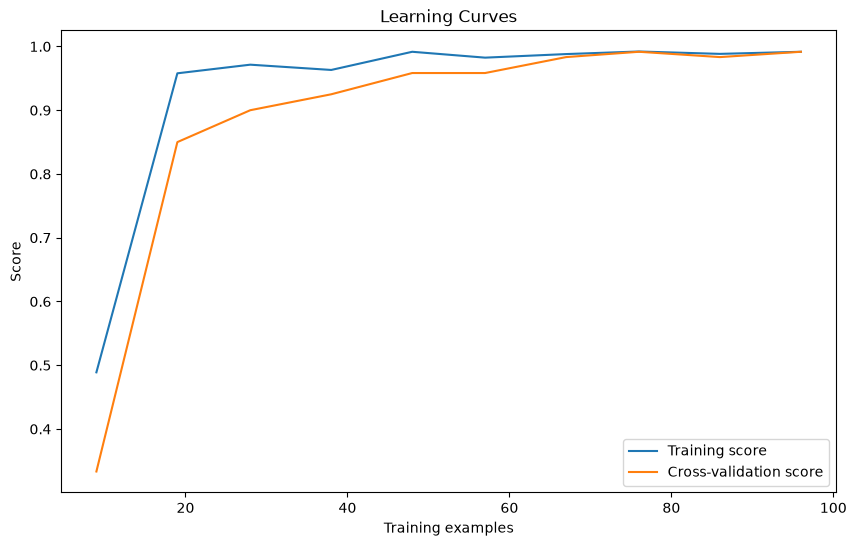

In [20]:
train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_,
    X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5
)

plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    np.mean(train_scores, axis=1),
    label='Training score'
)
plt.plot(
    train_sizes,
    np.mean(test_scores, axis=1),
    label='Cross-validation score'
)
plt.xlabel('Training examples')
plt.ylabel('Score')
plt.legend(loc='best')
plt.title('Learning Curves')
plt.show()

**Reading the learning curve.** With only 9 training samples the model is poor (training 0.49, validation 0.33); the validation score rises quickly and **keeps improving until about 70 samples**,
then flattens at ≈ 0.99 where it meets the training curve. The gap between the curves closes: the model is neither over-fitted (a persistent large gap) nor under-fitted (both curves low), and beyond
~100 training samples more data would add little. (The x-axis tops out at 96 because each of the 5 CV folds trains on 80 % of the 120 training samples.)

4.–6. Predictions on the **test** set and the confusion matrix:

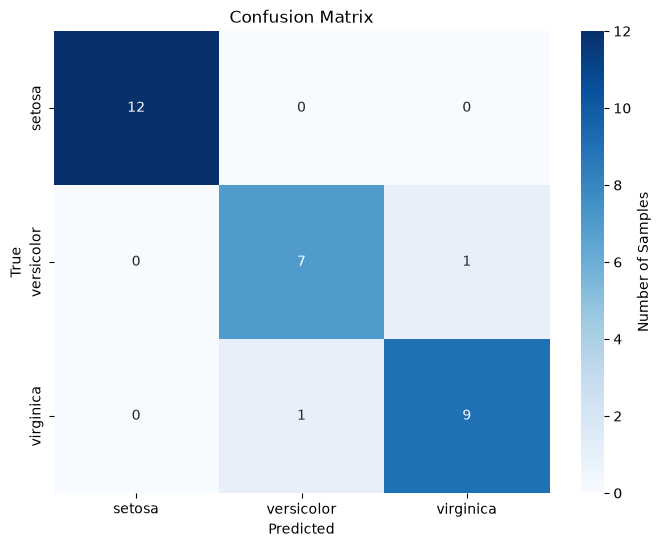

In [21]:
y_pred = grid_search.best_estimator_.predict(X_test)
class_names = iris.target_names

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Number of Samples'}
)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

Rows are the **true** class, columns the **predicted** class; the diagonal holds correct predictions and off-diagonal cells are the specific confusions (the book mentions TP/TN/FP/FN; for more
than two classes these are defined per class, treating that class as "positive" and the rest as "negative").

7.–9. The classification report as a styled table:

In [22]:
report_dict = classification_report(
    y_test, y_pred,
    target_names=class_names,
    output_dict=True
)
report_df = pd.DataFrame(report_dict).transpose()
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues', subset=['precision',
        'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
print("\nClassification Report:")
display(styled_df)


Classification Report:


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


The book notes that 100 % precision/recall for *setosa* would normally be suspicious but is expected here: setosa is linearly separable from the other two species (visible in the decision-boundary plot above).

**Extension — recompute the report numbers from the confusion matrix** to see where they come from:

In [23]:
for i, name in enumerate(class_names):
    tp = cm[i, i]; fp = cm[:, i].sum() - tp; fn = cm[i, :].sum() - tp
    prec = tp / (tp + fp) if tp + fp else 0; rec = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0
    print(f"{name:11s} TP={tp:2d} FP={fp} FN={fn}  precision={prec:.3f} recall={rec:.3f} F1={f1:.3f} support={cm[i].sum()}")
print("accuracy =", np.trace(cm), "/", cm.sum(), "=", round(np.trace(cm) / cm.sum(), 3))
print("macro avg F1   =", round(np.mean([report_dict[c]['f1-score'] for c in class_names]), 3))
print("weighted avg F1=", round(report_dict['weighted avg']['f1-score'], 3))

setosa      TP=12 FP=0 FN=0  precision=1.000 recall=1.000 F1=1.000 support=12
versicolor  TP= 7 FP=1 FN=1  precision=0.875 recall=0.875 F1=0.875 support=8
virginica   TP= 9 FP=1 FN=1  precision=0.900 recall=0.900 F1=0.900 support=10
accuracy = 28 / 30 = 0.933
macro avg F1   = 0.925
weighted avg F1= 0.933


### Understanding the evaluation metrics
* **Learning curves** — score vs training-set size; diagnose under-/over-fitting and whether more data would help.
* **Confusion matrix** — counts of every (true, predicted) pair.
* **Classification report** — per-class **precision** (of the points predicted as class $c$, how many truly are $c$) $=\dfrac{TP}{TP+FP}$,
  **recall / sensitivity** (of the true $c$ points, how many were found) $=\dfrac{TP}{TP+FN}$, **F1** $=\dfrac{2\,P\,R}{P+R}$ (harmonic mean — punishes a large imbalance between P and R),
  **accuracy** $=\dfrac{TP+TN}{TP+TN+FP+FN}$ (overall), **macro avg** = unweighted mean over classes, **weighted avg** = mean weighted by class support.

> **Book correction.** The printed formulas for precision/recall/F1/accuracy in the PDF are garbled by the typesetting (e.g. F1 is rendered as just "Recall"). The correct formulas are those above.

### There's more… imbalanced datasets
The book advises precision–recall curves or ROC-AUC instead of accuracy alone, and resampling. **Extension — why accuracy misleads** on a 95 : 5 problem:

In [24]:
from sklearn.datasets import make_classification
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

Xi, yi = make_classification(n_samples=2000, n_features=10, n_informative=4, weights=[0.95, 0.05], flip_y=0.01, class_sep=1.0, random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=0, stratify=yi)

models = {"always predict majority": None,
          "KNN k=5": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
          "KNN k=5, distance-weighted": make_pipeline(StandardScaler(), KNeighborsClassifier(5, weights="distance"))}
rows = []
for name, m in models.items():
    if m is None:
        pred = np.zeros_like(yi_te); proba = np.zeros(len(yi_te))
    else:
        m.fit(Xi_tr, yi_tr); pred = m.predict(Xi_te); proba = m.predict_proba(Xi_te)[:, 1]
    rows.append({"model": name, "accuracy": accuracy_score(yi_te, pred), "precision (minority)": precision_score(yi_te, pred, zero_division=0),
                 "recall (minority)": recall_score(yi_te, pred), "F1 (minority)": f1_score(yi_te, pred), "ROC-AUC": roc_auc_score(yi_te, proba),
                 "avg precision (PR-AUC)": average_precision_score(yi_te, proba)})
print("minority share in test set:", yi_te.mean().round(3))
pd.DataFrame(rows).set_index("model").round(3)

minority share in test set: 0.053


,accuracy,precision (minority),recall (minority),F1 (minority),ROC-AUC,avg precision (PR-AUC)
model,,,,,,
always predict majority,0.947,0.000,0.000,0.000,0.50,0.053
KNN k=5,0.948,0.667,0.062,0.114,0.79,0.305
"KNN k=5, distance-weighted",0.950,0.750,0.094,0.167,0.79,0.377


The model that *never* predicts the minority class scores ~95 % accuracy yet has zero recall — accuracy alone is useless here. Recall, F1 and the area under the ROC / precision–recall curves expose it.
Worse, the KNN models themselves find only **6–9 % of the minority cases**: with 5 neighbours, a minority point almost always has a majority-class majority around it, so KNN's vote is biased towards the common class
(its accuracy of 0.948–0.950 is barely above the 0.947 baseline). KNN has no `class_weight` option; remedies are resampling, lowering the decision threshold on `predict_proba`, or a different model.

**Extension — the two remedies the book names: resampling and precision–recall curves.** *Oversampling* duplicates minority examples (here by random sampling with replacement) and *undersampling* discards majority examples, until the classes are balanced.
It must be done **on the training set only, after the split** — resampling before splitting would put copies of the same point in both train and test (leakage). The test set stays untouched and imbalanced.

training class counts before: {0: 1324, 1: 76}


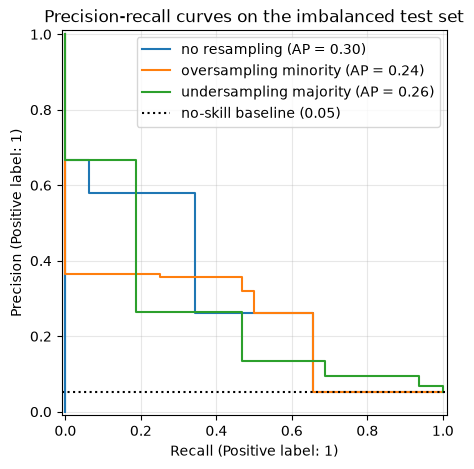

,n_train,accuracy,precision (minority),recall (minority),F1 (minority),avg precision (PR-AUC)
training set,,,,,,
no resampling,1400,0.948,0.667,0.062,0.114,0.305
oversampling minority,2648,0.917,0.320,0.500,0.390,0.238
undersampling majority,152,0.745,0.133,0.688,0.223,0.256


In [25]:
from sklearn.utils import resample
from sklearn.metrics import PrecisionRecallDisplay

maj, mino = Xi_tr[yi_tr == 0], Xi_tr[yi_tr == 1]
print("training class counts before:", {0: len(maj), 1: len(mino)})

# oversample the minority class up to the majority size
mino_up = resample(mino, replace=True, n_samples=len(maj), random_state=0)
X_over = np.vstack([maj, mino_up]); y_over = np.r_[np.zeros(len(maj), int), np.ones(len(mino_up), int)]
# undersample the majority class down to the minority size
maj_down = resample(maj, replace=False, n_samples=len(mino), random_state=0)
X_under = np.vstack([maj_down, mino]); y_under = np.r_[np.zeros(len(maj_down), int), np.ones(len(mino), int)]

variants = {"no resampling": (Xi_tr, yi_tr), "oversampling minority": (X_over, y_over), "undersampling majority": (X_under, y_under)}
rows = []; fig, ax = plt.subplots(figsize=(7, 5))
for name, (Xv, yv) in variants.items():
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(Xv, yv)
    pred = m.predict(Xi_te); proba = m.predict_proba(Xi_te)[:, 1]
    rows.append({"training set": name, "n_train": len(yv), "accuracy": accuracy_score(yi_te, pred), "precision (minority)": precision_score(yi_te, pred, zero_division=0),
                 "recall (minority)": recall_score(yi_te, pred), "F1 (minority)": f1_score(yi_te, pred), "avg precision (PR-AUC)": average_precision_score(yi_te, proba)})
    PrecisionRecallDisplay.from_predictions(yi_te, proba, name=name, ax=ax)
ax.axhline(yi_te.mean(), c="k", ls=":", label=f"no-skill baseline ({yi_te.mean():.2f})"); ax.legend(); ax.set_title("Precision-recall curves on the imbalanced test set"); ax.grid(alpha=.3)
plt.show()
pd.DataFrame(rows).set_index("training set").round(3)

Reading the table honestly:
* **Recall and F1 on the minority class jump**: from 6 % recall / F1 0.11 (no resampling) to 50 % / 0.39 (oversampling) and 69 % / 0.22 (undersampling). Resampling makes the model *pay attention* to the rare class.
* **It is a trade-off, not a free win.** Accuracy falls (0.95 → 0.92 → 0.75) and precision falls (0.67 → 0.32 → 0.13): many more majority cases are now flagged as minority. Undersampling throws away 95 % of the training data (152 rows left), which is why it hurts accuracy most.
* **The area under the PR curve does not improve** (0.31 → 0.24 and 0.26). Resampling mostly *moves the operating point* along a similar curve rather than making the model rank cases better — lowering the decision threshold on the original model would give a similar recall/precision trade-off without altering the data.
  (Duplicated minority points also make KNN over-confident near those exact points, which can slightly hurt ranking.)
* The dotted **no-skill baseline** in the PR plot equals the minority share (≈ 5 %); every curve is above it, i.e. KNN does carry signal.
* Choose the operating point by the cost of errors: if a missed minority case is expensive (fraud, disease) accept the lower precision; otherwise do not resample.

### Hands-on workflow (from the book)
Load KNN → `train_test_split` → `fit` → `predict` → `confusion_matrix` → precision/recall/F1 → plot the matrix with Matplotlib/Seaborn (all done above).

## 6. Practical exercises with KNN models

The book gives three exercises as step lists. The datasets are "of your choice"; I use bundled scikit-learn datasets, so everything runs offline.
Each exercise also reuses earlier chapters (imputation, scaling, pipelines).

### Exercise 1 — Build a KNN classifier (dataset requiring pre-processing)
Steps: load libraries → load data → **pre-process** → create and train → predict → evaluate.
I use the *Breast Cancer Wisconsin* data (569 samples, 30 numeric features with very different scales) and **inject 5 % missing values**, so that the pre-processing has real work to do:
imputation (Chapter 2) + scaling + KNN, all inside one pipeline.

In [26]:
from sklearn.datasets import load_breast_cancer
from sklearn.impute import SimpleImputer

bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data.copy(), bc.target
rng = np.random.default_rng(2024)
mask = rng.random(Xb.shape) < 0.05
Xb = Xb.mask(mask)                                                  # 5% of the cells become NaN
print("shape:", Xb.shape, "| missing cells:", int(Xb.isna().sum().sum()), f"({Xb.isna().mean().mean():.1%})", "| classes:", dict(zip(bc.target_names, np.bincount(yb))))
print("feature scale range: mean of 'area error' =", round(bc.data['mean area'].mean(), 1), "vs 'mean smoothness' =", round(bc.data['mean smoothness'].mean(), 3))

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.25, random_state=2024, stratify=yb)

# a KNN straight on the raw data cannot even run
try:
    KNeighborsClassifier().fit(Xb_tr, yb_tr)
except ValueError as e:
    print("\nKNN without pre-processing ->", type(e).__name__, ":", str(e).splitlines()[0])

shape: (569, 30) | missing cells: 841 (4.9%) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
feature scale range: mean of 'area error' = 654.9 vs 'mean smoothness' = 0.096

KNN without pre-processing -> ValueError : Input X contains NaN.


In [27]:
knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),     # fill NaNs
    ("scaler", StandardScaler()),                      # put features on one scale
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])
knn_pipe.fit(Xb_tr, yb_tr)                             # create and train
pred = knn_pipe.predict(Xb_te)                         # predict
print("Test accuracy:", round(accuracy_score(yb_te, pred), 4))
print(classification_report(yb_te, pred, target_names=bc.target_names))

# contrast: skip the scaler (impute only)
no_scale = Pipeline([("imputer", SimpleImputer(strategy="median")), ("knn", KNeighborsClassifier(5))]).fit(Xb_tr, yb_tr)
print("Without scaling, test accuracy:", round(no_scale.score(Xb_te, yb_te), 4))

Test accuracy: 0.9441
              precision    recall  f1-score   support

   malignant       0.96      0.89      0.92        53
      benign       0.94      0.98      0.96        90

    accuracy                           0.94       143
   macro avg       0.95      0.93      0.94       143
weighted avg       0.94      0.94      0.94       143

Without scaling, test accuracy: 0.9301


Scaling is worth about 1.4 points of accuracy here (0.944 vs 0.930, i.e. 2 of the 143 test samples) — a smaller effect than on Wine, because several of the largest-range features happen to be informative.
Evaluation (step 6) used the held-out test set and a per-class report; for malignant-tumour detection *recall of the malignant class* is the metric that matters most (a missed cancer is worse than a false alarm).

### Exercise 2 — Tune hyperparameters with grid search on a different dataset
Steps: load a different dataset → pre-process → set up the grid search → fit → evaluate the best model. I use the *Wine* data with the scaler **inside** the pipeline.

combinations: 120 x 5 folds
Best parameters: {'knn__metric': 'manhattan', 'knn__n_neighbors': 11, 'knn__weights': 'uniform'}
Best CV accuracy: 0.9698
Test accuracy   : 0.9778


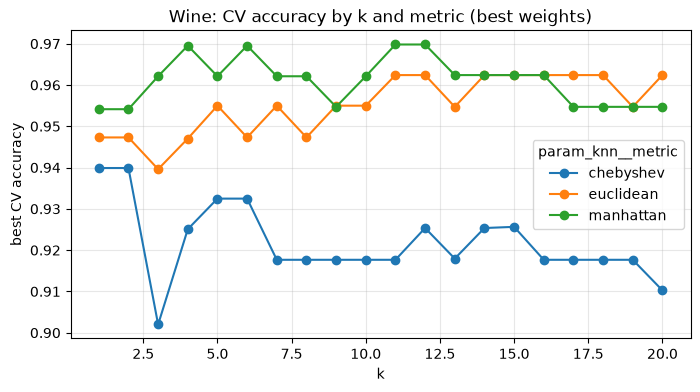

In [28]:
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.25, random_state=2024, stratify=yw)

pipe_w = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
param_grid_w = {
    "knn__n_neighbors": list(range(1, 21)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "chebyshev"],
}
gs_w = GridSearchCV(pipe_w, param_grid_w, cv=StratifiedKFold(5, shuffle=True, random_state=2024), scoring="accuracy")
gs_w.fit(Xw_tr, yw_tr)

print("combinations:", len(gs_w.cv_results_["params"]), "x 5 folds")
print("Best parameters:", gs_w.best_params_)
print("Best CV accuracy:", round(gs_w.best_score_, 4))
print("Test accuracy   :", round(gs_w.score(Xw_te, yw_te), 4))

# accuracy by k for each metric (best weights), to see the landscape rather than only the winner
r = pd.DataFrame(gs_w.cv_results_)
r["k"] = r["param_knn__n_neighbors"].astype(int)
land = r.groupby(["param_knn__metric", "k"])["mean_test_score"].max().unstack(0)
land.plot(figsize=(8, 4), marker="o", ylabel="best CV accuracy", xlabel="k", title="Wine: CV accuracy by k and metric (best weights)")
plt.grid(alpha=.3); plt.show()

Several configurations are within a fraction of a point of each other, so the "best" parameters are partly a matter of chance; the landscape plot shows a broad plateau, which is what you want
(a model whose accuracy does not depend sharply on one lucky value). Report the test accuracy once, after the search.

### Exercise 3 — Evaluate a KNN classifier (multi-class: handwritten digits)
Steps: load → pre-process → create and train → predict → evaluate. The 10-class digits data gives a confusion matrix that is far more informative than Iris'.

Test accuracy: 0.9733


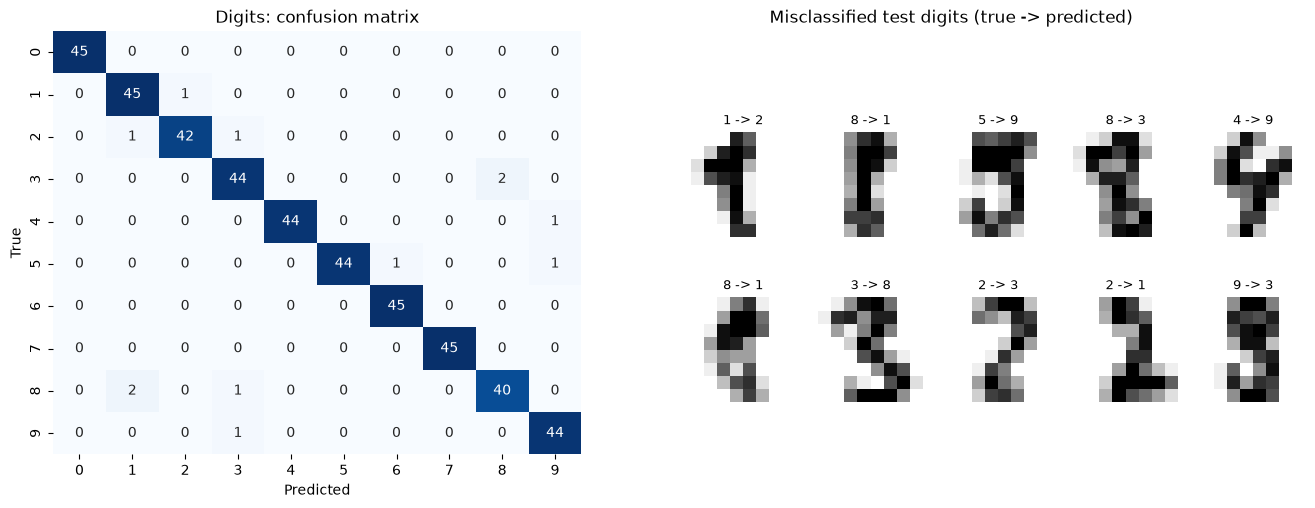

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        45
           1      0.938     0.978     0.957        46
           2      0.977     0.955     0.966        44
           3      0.936     0.957     0.946        46
           4      1.000     0.978     0.989        45
           5      1.000     0.957     0.978        46
           6      0.978     1.000     0.989        45
           7      1.000     1.000     1.000        45
           8      0.952     0.930     0.941        43
           9      0.957     0.978     0.967        45

    accuracy                          0.973       450
   macro avg      0.974     0.973     0.973       450
weighted avg      0.974     0.973     0.973       450



In [29]:
from sklearn.datasets import load_digits

dg = load_digits()
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(dg.data, dg.target, test_size=0.25, random_state=2024, stratify=dg.target)

digit_knn = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=3, weights="distance"))]).fit(Xd_tr, yd_tr)
yd_pred = digit_knn.predict(Xd_te)
print("Test accuracy:", round(accuracy_score(yd_te, yd_pred), 4))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(confusion_matrix(yd_te, yd_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0], cbar=False)
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True"); ax[0].set_title("Digits: confusion matrix")

wrong = np.where(yd_pred != yd_te)[0][:10]
ax[1].axis("off"); ax[1].set_title("Misclassified test digits (true -> predicted)")
for j, i in enumerate(wrong):
    sub = fig.add_axes([0.55 + (j % 5) * 0.085, 0.50 - (j // 5) * 0.3, 0.07, 0.2])
    sub.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); sub.set_title(f"{yd_te[i]} -> {yd_pred[i]}", fontsize=9); sub.axis("off")
plt.show()
print(classification_report(yd_te, yd_pred, digits=3))

The model is very accurate on this task; the few errors involve visually similar shapes (see the misclassified examples). Per-class recall tells you *which* digits are hard — information
accuracy alone does not give.

**Extension — KNN also does regression** (the book mentions "regression tasks" and "average of neighbours"): predict California house prices from the 8 features, with scaling, using the
data cached in Chapter 2.

In [30]:
from sklearn.datasets import fetch_california_housing
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error

Xh, yh = fetch_california_housing(return_X_y=True, as_frame=True)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.2, random_state=2024)

rows = []
for k in (1, 5, 15, 40):
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(Xh_tr, yh_tr)
    p = m.predict(Xh_te)
    rows.append({"k": k, "R2 (test)": r2_score(yh_te, p), "RMSE (test)": np.sqrt(mean_squared_error(yh_te, p)), "R2 (train)": m.score(Xh_tr, yh_tr)})
pd.DataFrame(rows).set_index("k").round(3)

,R2 (test),RMSE (test),R2 (train)
k,,,
1,0.543,0.790,1.000
5,0.700,0.641,0.787
15,0.700,0.641,0.729
40,0.683,0.659,0.691


For regression the prediction is the **mean target of the k neighbours**. Training R² is 1.0 for `k=1` (memorisation) while test R² is much lower — the same bias–variance story as for classification.
(Test R² ≈ 0.70 at `k = 5–15` is comparable to Chapter 2's best linear pipeline (0.69), without any hand-made polynomial features: KNN is non-parametric and can follow the non-linear location effect.)

### There's more… (book)
After mastering the basics: use distance metrics for clustering and regression, and explore DBSCAN, mean shift, spectral clustering, kernel density and the **radius neighbors classifier**
(`RadiusNeighborsClassifier`: votes among *all* points within a fixed radius instead of a fixed number `k`) — all in scikit-learn (clustering is covered in Chapter 10).

### Theory (for the exercises)
* **Pre-processing for KNN:** impute (distances need complete data) → scale (distances need comparable features) → optionally reduce dimension (distances need relevant features). All inside the pipeline so they are fit on training data only.
* **Which metric for which error?** In medical screening favour **recall**; in spam filtering favour **precision**; for balanced multi-class problems accuracy and macro-F1 are fine.
* **KNN regression** is a local averaging smoother; `weights='distance'` gives a distance-weighted (inverse-distance) average.

## Chapter takeaways
1. **Similarity = distance.** Euclidean (L2), Manhattan (L1) and Minkowski (Lp) differ in how they combine coordinate differences; scikit-learn's `minkowski` defaults to `p=2`, i.e. Euclidean.
2. **KNN** predicts by majority vote (or mean) of the `k` nearest training points; it is a lazy learner with no training phase and a slow prediction phase.
3. **`k` controls bias vs variance:** small `k` overfits (jagged boundary), large `k` underfits (blurred boundary); choose it by cross-validation.
4. **Scale first, mind the dimension:** scaling matters more than which Lp metric you pick, and irrelevant features steadily degrade KNN.
5. **Tune with `GridSearchCV`/`RandomizedSearchCV`, then evaluate once on a held-out test set;** many configurations tie on easy data.
6. **Evaluate beyond accuracy:** learning curves for diagnosis, the confusion matrix for *which* errors, and precision / recall / F1 (and ROC-AUC / PR-AUC for imbalanced data).

### Book corrections noted in this notebook
| Where | Book says / does | Actually |
|---|---|---|
| Metric comparison (Fig. 4.2) | compares Euclidean, Manhattan **and** Minkowski | `minkowski` has `p=2` by default = Euclidean (identical accuracies); set `p` for a different metric |
| Circles dataset | `make_circles` without `random_state` | results change on every run; Manhattan's "win" was luck (see repeated experiment) |
| Checkerboard dataset | 300 samples, variables named `moons` | 17×17 = 289 grid points; it is a checkerboard, not moons |
| Cross-validation | "adds an element of randomization" | it gives multiple train/validation splits for a more reliable estimate (randomness only if you shuffle) |
| Metric formulas | printed garbled (F1 shown as "Recall") | precision $=TP/(TP+FP)$, recall $=TP/(TP+FN)$, F1 $=2PR/(P+R)$ |
| Code listings | missing imports (`cross_val_score`, `classification_report`, `pandas`, `numpy`, `matplotlib`) | added in this notebook |

*Next: Chapter 5 — Linear Models and Regularization.*